# Interactive XDS time-velocity maps

Notebook para explorar mapas tipo Fig. 2 del Exomoon Velocity Shadow (EXOVEL). Permite cambiar el preset fisico, la ventana temporal, el centrado de fase y algunos parametros numericos sin editar el script de linea de comandos.

La configuracion recomendada para la figura tipo paper actual es:

```text
preset = "paper-showcase"
center_mode = "peak"
time_start = -12
time_end = 12
```


In [225]:
from __future__ import annotations

from dataclasses import replace
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
PROJECT_ROOT = None
for candidate in candidates:
    if (candidate / "src" / "xds").exists():
        PROJECT_ROOT = candidate
        break
    if (candidate / "xds" / "src" / "xds").exists():
        PROJECT_ROOT = candidate / "xds"
        break
if PROJECT_ROOT is None:
    raise RuntimeError(f"Could not locate xds/src/xds from cwd={cwd}")

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from xds.config import MoonConfig, PlanetConfig, SimulationConfig
from xds.diagnostics import map_diagnostics
from xds.spectra import run_xds_model

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROJECT_ROOT

PosixPath('/Users/sucerqum/Documents/Playground/xds')

## Presets fisicos

`fiducial` reproduce el caso ilustrativo inicial. `lhs-best` usa el mejor candidato del barrido Latin Hypercube refinado. `paper-showcase` usa una configuracion menos extrema: planeta tipo sub-Jupiter/Jupiter y una luna de radio terrestre.

In [226]:
def build_configs(preset: str = "fiducial") -> tuple[PlanetConfig, MoonConfig, SimulationConfig, str]:
    if preset == "fiducial":
        planet = PlanetConfig(v_eq=12.0, line_sigma=1.5, line_depth=1.0)
        moon = MoonConfig(radius=0.2, semi_major_axis=3.0, period=5.0, phase=0.08)
        sim = SimulationConfig(
            transit_duration=5.0,
            n_times=1000,
            n_longitudes=181,
            n_latitudes=121,
            n_velocities=501,
            velocity_min=-25.0,
            velocity_max=25.0,
            use_illumination_shadow=True,
            use_observer_occultation=True,
        )
        return planet, moon, sim, "fiducial"

    if preset == "lhs-best":
        planet = PlanetConfig(v_eq=10.052449786472337, line_sigma=1.5, line_depth=1.0)
        moon = MoonConfig(
            radius=0.34237930871226385,
            semi_major_axis=2.1680725360270703,
            period=58.950105370121975,
            phase=0.08,
        )
        sim = SimulationConfig(
            transit_duration=2.862057477656129,
            n_times=281,
            n_longitudes=181,
            n_latitudes=121,
            n_velocities=501,
            velocity_min=-25.0,
            velocity_max=25.0,
            use_illumination_shadow=True,
            use_observer_occultation=True,
        )
        return planet, moon, sim, "lhs_best"

    if preset == "paper-showcase":
        # Less extreme paper showcase. The moon radius is approximately R_earth/R_jupiter,
        # and P_m is the circular period at a_m=3 R_p for a 0.7 M_J, 1.1 R_J host.
        planet = PlanetConfig(v_eq=12.0, line_sigma=1.5, line_depth=1.0)
        moon = MoonConfig(
            radius=0.12,
            semi_major_axis=3.0,
            period=21.238292071543107,
            phase=0.08,
        )
        sim = SimulationConfig(
            transit_duration=16.0,
            n_times=281,
            n_longitudes=181,
            n_latitudes=121,
            n_velocities=501,
            velocity_min=-25.0,
            velocity_max=25.0,
            use_illumination_shadow=True,
            use_observer_occultation=True,
        )
        return planet, moon, sim, "paper_showcase"

    raise ValueError(f"Unknown preset: {preset}")


def with_sim_window(sim: SimulationConfig, window_hours: float | None) -> SimulationConfig:
    if window_hours is None:
        return sim
    return replace(sim, transit_duration=float(window_hours))


def recenter_moon_on_peak(planet: PlanetConfig, moon: MoonConfig, sim: SimulationConfig) -> MoonConfig:
    scan_sim = SimulationConfig(
        transit_duration=moon.period,
        n_times=721,
        n_longitudes=max(61, sim.n_longitudes // 2),
        n_latitudes=max(41, sim.n_latitudes // 2),
        velocity_min=sim.velocity_min,
        velocity_max=sim.velocity_max,
        n_velocities=101,
        star_direction=sim.star_direction,
        observer_direction=sim.observer_direction,
        use_illumination_shadow=sim.use_illumination_shadow,
        use_observer_occultation=sim.use_observer_occultation,
    )
    scan = run_xds_model(planet, moon, scan_sim)
    peak_time = float(scan.time[int(np.argmax(scan.combined_fraction))])
    return replace(moon, phase=(moon.phase + peak_time / moon.period) % 1.0)


def shift_moon_phase(moon: MoonConfig, time_offset_hours: float) -> MoonConfig:
    return replace(moon, phase=(moon.phase + time_offset_hours / moon.period) % 1.0)

## Parametros interactivos

Edita esta celda y vuelve a ejecutar desde aqui. Para una ventana asimetrica usa `time_start` y `time_end`; si ambos son `None`, se usa `window_hours` o la duracion del preset.

In [244]:
preset = "paper-showcase" # "fiducial", "lhs-best", or "paper-showcase"
center_mode = "peak"      # "midtransit" or "peak"

# Ventana recomendada para el paper actual:
time_start = -5
time_end = 13

# Si time_start/time_end son None, usa esta ventana simetrica. Si tambien es None, usa Tdur del preset.
window_hours = None

# Resolucion numerica. Baja estos valores para iterar mas rapido.
nr=2
n_times = nr*281
n_longitudes = nr*181
n_latitudes = nr*121
n_velocities = nr*501

# Estetica.
reference_cmap = "inferno"
differential_cmap = "berlin_r"
save_outputs = True
tag = "interactive_paper_showcase"

In [228]:
def prepare_run(
    preset: str,
    center_mode: str,
    time_start: float | None,
    time_end: float | None,
    window_hours: float | None,
) -> tuple[PlanetConfig, MoonConfig, SimulationConfig, float, str]:
    planet, moon, sim, default_tag = build_configs(preset)
    sim = replace(
        sim,
        n_times=n_times,
        n_longitudes=n_longitudes,
        n_latitudes=n_latitudes,
        n_velocities=n_velocities,
    )

    if (time_start is None) != (time_end is None):
        raise ValueError("time_start and time_end must both be set or both be None")

    if time_start is not None:
        if time_end <= time_start:
            raise ValueError("time_end must be larger than time_start")
        run_window = time_end - time_start
        time_offset = 0.5 * (time_start + time_end)
    else:
        run_window = window_hours
        time_offset = 0.0

    sim = with_sim_window(sim, run_window)
    if center_mode == "peak":
        moon = recenter_moon_on_peak(planet, moon, sim)
    elif center_mode != "midtransit":
        raise ValueError("center_mode must be 'midtransit' or 'peak'")

    if time_offset != 0.0:
        moon = shift_moon_phase(moon, time_offset)

    return planet, moon, sim, time_offset, default_tag


planet, moon, sim, time_offset, default_tag = prepare_run(
    preset, center_mode, time_start, time_end, window_hours
)

print("Planet:", planet)
print("Moon:", moon)
print("Simulation:", sim)
print("time_offset =", time_offset)

Planet: PlanetConfig(radius=1.0, v_eq=12.0, spin_inclination=90.0, spin_obliquity=0.0, line_depth=1.0, line_sigma=1.5, atmosphere_half_width=0.03)
Moon: MoonConfig(radius=0.12, semi_major_axis=3.0, period=21.238292071543107, phase=0.24056128388149495, inclination=90.0, longitude_node=0.0, argument_pericenter=0.0, eccentricity=0.0)
Simulation: SimulationConfig(transit_duration=18.0, n_times=562, n_longitudes=362, n_latitudes=242, velocity_min=-25.0, velocity_max=25.0, n_velocities=1002, star_direction=(-1.0, 0.0, 0.0), observer_direction=(-1.0, 0.0, 0.0), use_illumination_shadow=True, use_observer_occultation=True)
time_offset = 4.0


## Ejecutar modelo

In [240]:
result = run_xds_model(planet, moon, sim)
plot_time = result.time + time_offset
diagnostics = map_diagnostics(result.time, result.velocity, result.delta_absorption)

print(f"time window = [{plot_time[0]:.2f}, {plot_time[-1]:.2f}] h")
print(f"max |Delta A| = {np.max(np.abs(result.delta_absorption)):.5f}")
print(f"peak shadowed fraction = {np.max(result.combined_fraction):.5f}")

time window = [-5.00, 13.00] h
max |Delta A| = 0.00892
peak shadowed fraction = 0.00914


## Figura tipo Fig. 2

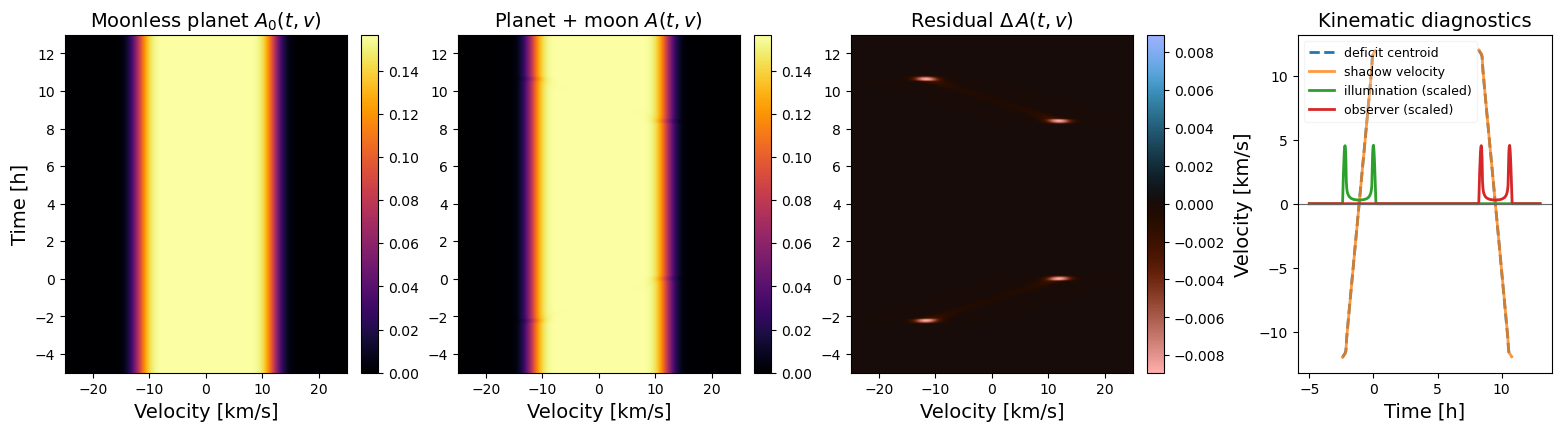

In [245]:
def plot_xds_figure(result, plot_time, diagnostics, reference_cmap="inferno", differential_cmap="RdBu_r"):
    extent = [result.velocity[0], result.velocity[-1], plot_time[0], plot_time[-1]]
    vmax = np.max(result.reference_absorption)
    dmax = np.max(np.abs(result.delta_absorption))

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(15.5, 4.2),
        gridspec_kw={"width_ratios": [1.0, 1.0, 1.0, 0.9]},
        constrained_layout=True,
    )

    panels = [
        (result.reference_absorption, "Moonless planet $A_0(t,v)$", reference_cmap, 0.0, vmax, r""),
        (result.absorption, "Planet + moon $A(t,v)$", reference_cmap, 0.0, vmax, r""),
        (result.delta_absorption, r"Residual $\Delta \,A(t,v)$", differential_cmap, -dmax, dmax, r""),
    ]
    fs=14
    for ax, (data, title, cmap, vmin, vmax_panel, cbar_label) in zip(axes[:3], panels):
        im = ax.imshow(
            data,
            origin="lower",
            aspect="auto",
            extent=extent,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax_panel,
        )
        ax.set_title(title, fontsize=fs)
        ax.set_xlabel("Velocity [km/s]", fontsize=fs)
        #ax.set_ylabel("Time [h]")
        cbar = fig.colorbar(im, ax=ax, fraction=0.1)
        cbar.set_label(cbar_label)
    ax = axes[0]
    ax.set_ylabel("Time [h]", fontsize=fs)

    lw=2

    ax = axes[3]
    ax.plot(plot_time, diagnostics.centroid, '--', lw=lw, label="deficit centroid")
    ax.plot(plot_time, diagnostics.shadow_velocity, lw=lw, alpha=0.8, label="shadow velocity")
    ax.plot(plot_time, 500.0 * result.illumination_fraction, lw=lw, label="illumination (scaled)")
    ax.plot(plot_time, 500.0 * result.observer_fraction, lw=lw,label="observer (scaled)")
    ax.axhline(0.0, color="0.4", linewidth=0.8)
    ax.set_title("Kinematic diagnostics", fontsize=fs)
    ax.set_xlabel("Time [h]", fontsize=fs)
    ax.set_ylabel("Velocity [km/s]", fontsize=fs)
    ax.legend(fontsize=9, framealpha=0.2)
    return fig, axes


fig, axes = plot_xds_figure(result, plot_time, diagnostics, reference_cmap, differential_cmap)

## Guardar PNG y NPZ

In [231]:
if save_outputs:
    output_png = OUTPUT_DIR / f"fig2_xds_maps_{tag}.png"
    output_npz = OUTPUT_DIR / f"fig2_xds_maps_{tag}.npz"
    fig.savefig(output_png, dpi=600)
    np.savez(
        output_npz,
        time=plot_time,
        model_time=result.time,
        velocity=result.velocity,
        reference_absorption=result.reference_absorption,
        absorption=result.absorption,
        delta_absorption=result.delta_absorption,
        moon_positions=result.moon_positions,
        illumination_fraction=result.illumination_fraction,
        observer_fraction=result.observer_fraction,
        combined_fraction=result.combined_fraction,
        centroid=diagnostics.centroid,
        skewness=diagnostics.skewness,
        blue_signal=diagnostics.blue_signal,
        red_signal=diagnostics.red_signal,
        shadow_velocity=diagnostics.shadow_velocity,
        shadow_strength=diagnostics.shadow_strength,
        planet_v_eq=planet.v_eq,
        moon_radius=moon.radius,
        moon_semi_major_axis=moon.semi_major_axis,
        moon_period=moon.period,
        moon_phase=moon.phase,
        transit_duration=sim.transit_duration,
        time_offset=time_offset,
    )
    print(output_png)
    print(output_npz)

/Users/sucerqum/Documents/Playground/xds/outputs/fig2_xds_maps_interactive_paper_showcase.png
/Users/sucerqum/Documents/Playground/xds/outputs/fig2_xds_maps_interactive_paper_showcase.npz


## Comparar varias ventanas rapidamente

Esta celda es opcional. Genera solo el panel diferencial para varias ventanas temporales.

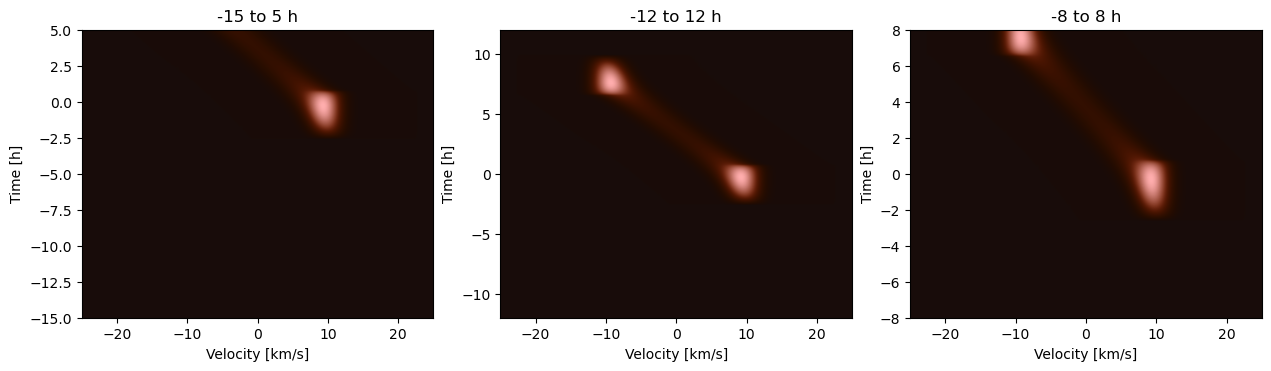

In [202]:
def quick_delta_for_window(time_start, time_end, preset="lhs-best", center_mode="peak"):
    planet, moon, sim, time_offset, _ = prepare_run(preset, center_mode, time_start, time_end, None)
    result = run_xds_model(planet, moon, sim)
    return result, result.time + time_offset


windows = [(-15, 5), (-12, 12), (-8, 8)]
fig, axes = plt.subplots(1, len(windows), figsize=(4.2 * len(windows), 3.6), constrained_layout=True)
for ax, window in zip(np.atleast_1d(axes), windows):
    r, t = quick_delta_for_window(*window)
    dmax = np.max(np.abs(r.delta_absorption))
    ax.imshow(
        r.delta_absorption,
        origin="lower",
        aspect="auto",
        extent=[r.velocity[0], r.velocity[-1], t[0], t[-1]],
        cmap=differential_cmap,
        vmin=-dmax,
        vmax=dmax,
    )
    ax.set_title(f"{window[0]} to {window[1]} h")
    ax.set_xlabel("Velocity [km/s]")
    ax.set_ylabel("Time [h]")

## Alternative diagnostics panel

This optional panel separates kinematic quantities from blocking fractions. The left axis shows velocities only; the right axis shows the illumination and observer-line blocking fractions without arbitrary scale factors.


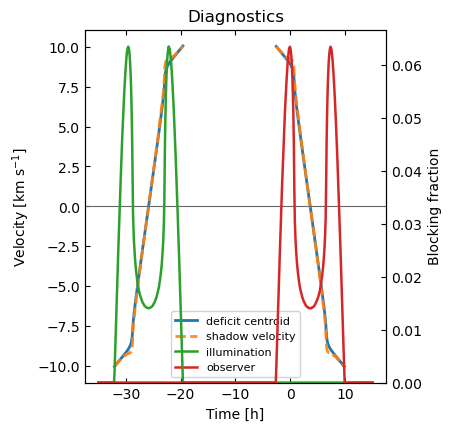

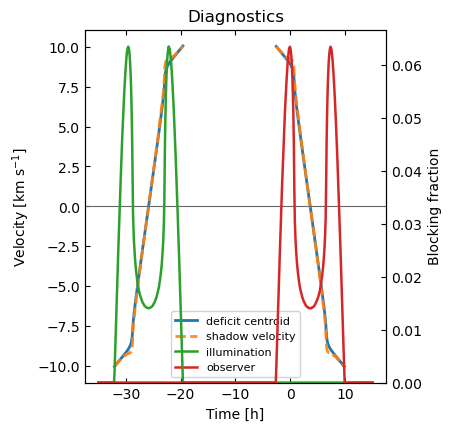

In [136]:
def plot_diagnostics_dual_axis(result, plot_time, diagnostics, title="Diagnostics"):
    """Plot EXOVEL diagnostics with velocities and blocking fractions on separate axes."""
    fig, ax_vel = plt.subplots(figsize=(4.4, 4.2), constrained_layout=True)

    line_centroid, = ax_vel.plot(
        plot_time,
        diagnostics.centroid,
        color="tab:blue",
        lw=2.0,
        linestyle="-",
        label="deficit centroid",
    )
    line_shadow, = ax_vel.plot(
        plot_time,
        diagnostics.shadow_velocity,
        color="tab:orange",
        lw=2.0,
        linestyle="--",
        alpha=0.9,
        label="shadow velocity",
    )
    ax_vel.axhline(0.0, color="0.4", linewidth=0.8)
    ax_vel.set_title(title)
    ax_vel.set_xlabel("Time [h]")
    ax_vel.set_ylabel(r"Velocity [km s$^{-1}$]")
    ax_vel.tick_params(direction="in", top=True)

    ax_frac = ax_vel.twinx()
    line_illum, = ax_frac.plot(
        plot_time,
        result.illumination_fraction,
        color="tab:green",
        lw=1.8,
        label="illumination",
    )
    line_obs, = ax_frac.plot(
        plot_time,
        result.observer_fraction,
        color="tab:red",
        lw=1.8,
        label="observer",
    )
    ax_frac.set_ylabel("Blocking fraction")
    ax_frac.set_ylim(bottom=0.0)
    ax_frac.tick_params(direction="in", top=True)

    lines = [line_centroid, line_shadow, line_illum, line_obs]
    labels = [line.get_label() for line in lines]
    ax_vel.legend(lines, labels, fontsize=8, framealpha=0.85, loc="best")
    return fig, (ax_vel, ax_frac)


fig_diag, axes_diag = plot_diagnostics_dual_axis(result, plot_time, diagnostics)
fig_diag


## Full Fig. 2 with dual-axis diagnostics

This version reproduces the four-panel figure but replaces the diagnostics panel with the dual-axis version above.


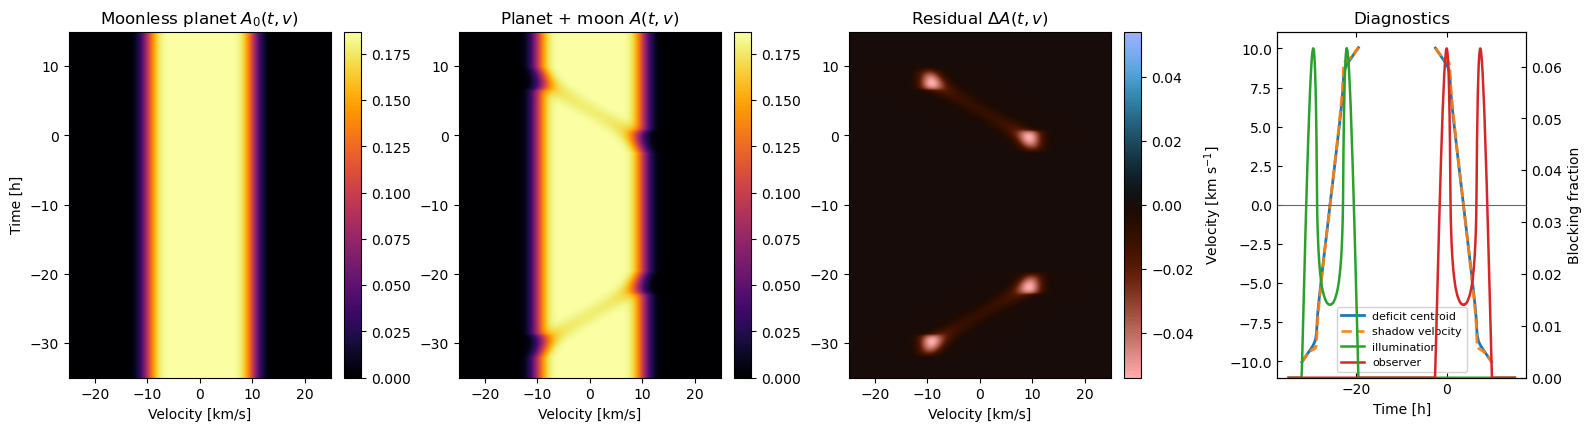

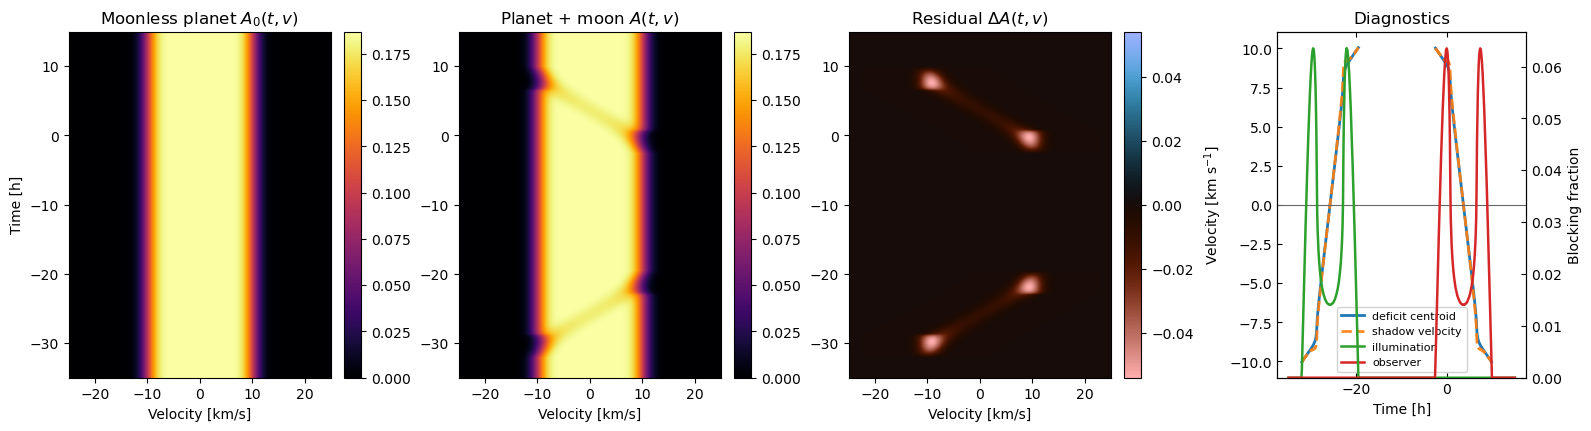

In [137]:
def plot_xds_figure_dual_diagnostics(result, plot_time, diagnostics, reference_cmap="magma", differential_cmap="RdBu_r"):
    extent = [result.velocity[0], result.velocity[-1], plot_time[0], plot_time[-1]]
    vmax = np.max(result.reference_absorption)
    dmax = np.max(np.abs(result.delta_absorption))

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(15.8, 4.2),
        gridspec_kw={"width_ratios": [1.0, 1.0, 1.0, 0.95]},
        constrained_layout=True,
    )

    panels = [
        (result.reference_absorption, "Moonless planet $A_0(t,v)$", reference_cmap, 0.0, vmax),
        (result.absorption, "Planet + moon $A(t,v)$", reference_cmap, 0.0, vmax),
        (result.delta_absorption, r"Residual $\Delta A(t,v)$", differential_cmap, -dmax, dmax),
    ]
    for ax, (data, title, cmap, vmin, vmax_panel) in zip(axes[:3], panels):
        im = ax.imshow(
            data,
            origin="lower",
            aspect="auto",
            extent=extent,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax_panel,
        )
        ax.set_title(title)
        ax.set_xlabel("Velocity [km/s]")
        fig.colorbar(im, ax=ax, fraction=0.1)
    axes[0].set_ylabel("Time [h]")

    ax_vel = axes[3]
    line_centroid, = ax_vel.plot(plot_time, diagnostics.centroid, color="tab:blue", lw=2.0, label="deficit centroid")
    line_shadow, = ax_vel.plot(plot_time, diagnostics.shadow_velocity, color="tab:orange", lw=2.0, ls="--", alpha=0.9, label="shadow velocity")
    ax_vel.axhline(0.0, color="0.4", linewidth=0.8)
    ax_vel.set_title("Diagnostics")
    ax_vel.set_xlabel("Time [h]")
    ax_vel.set_ylabel(r"Velocity [km s$^{-1}$]")
    ax_vel.tick_params(direction="in", top=True)

    ax_frac = ax_vel.twinx()
    line_illum, = ax_frac.plot(plot_time, result.illumination_fraction, color="tab:green", lw=1.8, label="illumination")
    line_obs, = ax_frac.plot(plot_time, result.observer_fraction, color="tab:red", lw=1.8, label="observer")
    ax_frac.set_ylabel("Blocking fraction")
    ax_frac.set_ylim(bottom=0.0)
    ax_frac.tick_params(direction="in", top=True)

    lines = [line_centroid, line_shadow, line_illum, line_obs]
    ax_vel.legend(lines, [line.get_label() for line in lines], fontsize=8, framealpha=0.85, loc="best")
    return fig, axes, ax_frac


fig_dual, axes_dual, ax_frac_dual = plot_xds_figure_dual_diagnostics(
    result, plot_time, diagnostics, reference_cmap, differential_cmap
)
fig_dual


In [138]:
# Optional save for the dual-axis version.
if save_outputs:
    output_dual_png = OUTPUT_DIR / f"fig2_xds_maps_{tag}_dual_diagnostics.png"
    fig_dual.savefig(output_dual_png, dpi=180)
    print(output_dual_png)


/Users/sucerqum/Documents/Playground/xds/outputs/fig2_xds_maps_interactive_lhs_best_m15_p5h_dual_diagnostics.png


## Local deficit centroid diagnostic

The global deficit centroid uses all negative residual pixels. The local centroid below uses only velocities within `half_width_km_s` of the deepest deficit pixel at each time. This helps diagnose whether extended wings or multiple simultaneous deficits bias the global centroid.


In [ ]:
def local_deficit_centroid(delta_absorption, velocity, half_width_km_s=3.0):
    """Centroid of D=max(-DeltaA,0) near the deepest deficit at each time."""
    deficit = np.clip(-delta_absorption, 0.0, None)
    total = deficit.sum(axis=1)
    peak_idx = np.argmax(deficit, axis=1)
    peak_velocity = velocity[peak_idx]
    local = np.abs(velocity[None, :] - peak_velocity[:, None]) <= half_width_km_s
    local_deficit = np.where(local, deficit, 0.0)
    local_total = local_deficit.sum(axis=1)
    centroid = (local_deficit * velocity[None, :]).sum(axis=1) / np.where(local_total > 0.0, local_total, np.nan)
    centroid = np.where(total > 0.0, centroid, np.nan)
    peak_velocity = np.where(total > 0.0, peak_velocity, np.nan)
    return centroid, peak_velocity

local_centroid, peak_velocity_check = local_deficit_centroid(
    result.delta_absorption, result.velocity, half_width_km_s=3.0
)

print("max |shadow_velocity - peak_velocity_check| =", np.nanmax(np.abs(diagnostics.shadow_velocity - peak_velocity_check)))
print("global centroid min/max =", np.nanmin(diagnostics.centroid), np.nanmax(diagnostics.centroid))
print("local centroid min/max =", np.nanmin(local_centroid), np.nanmax(local_centroid))


In [ ]:
fig_local, ax = plt.subplots(figsize=(5.2, 3.6), constrained_layout=True)
ax.plot(plot_time, diagnostics.centroid, lw=2.0, label="global deficit centroid")
ax.plot(plot_time, local_centroid, lw=2.0, ls="--", label="local deficit centroid")
ax.plot(plot_time, diagnostics.shadow_velocity, lw=1.6, ls=":", color="0.2", label="shadow velocity")
ax.axhline(0.0, color="0.4", linewidth=0.8)
ax.set_xlabel("Time [h]")
ax.set_ylabel(r"Velocity [km s$^{-1}$]")
ax.set_title("Centroid check")
ax.tick_params(direction="in", top=True, right=True)
ax.legend(fontsize=8, framealpha=0.85)
fig_local
